In [1]:
import numpy as np
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

In [2]:
# Question 1
A = np.array([[2, 0], [0, 1]])
b = np.array([1, 1])

X = np.array([[0, 0]])
R = np.array([A @ X[0] - b])
P = -R
Alpha = np.array([])
Beta = np.array([0])

for i in range(2):
    Alpha = np.append(Alpha, np.linalg.norm(R[i]) ** 2 / (P[i].T @ A @ P[i]))
    X = np.vstack((X, X[i] + Alpha[i] * P[i]))
    R = np.vstack((R, R[i] + Alpha[i] * A @ P[i]))
    Beta = np.append(Beta, (R[i + 1].T @ R[i + 1]) / (R[i].T @ R[i]))
    P = np.vstack((P, Beta[i+1] * P[i] - R[i + 1]))
    
    # print(f'Alpha{i}={Alpha[i]}')
    # print(f'X{i+1}={X[-1]}')
    # print(f'R{i+1}={R[-1]}')
    # print(f'Beta{i+1}={Beta[i+1]}')
    # print(f'P{i+1}={P[-1]}')
    
    if np.linalg.norm(R[i + 1]) < 1e-8:
        break

X[-1]

array([0.5, 1. ])

In [3]:
# Question 4a
def find_min(n):
    A = np.diag(np.arange(n) + 1)
    b = np.ones(n)
    return np.linalg.solve(A, b)

x_20_min = find_min(20)
x_100_min = find_min(100)

In [4]:
def train(n, update, mu=1e-2):
    A = np.diag(np.arange(n) + 1)
    b = np.ones(n)
    x = np.zeros(n)
    
    loss = lambda x: 1/2 * x.T @ A @ x - b.T @ x
    grad = lambda x: A @ x - b
    
    r = grad(x)
    p = -r
    
    kwargs = {"x": x, "r": r, "p": p}
    x_star = find_min(n)
    min_loss = loss(x_star)
    losses = np.array([loss(x) - min_loss])
    distances = np.array([np.linalg.norm(x - x_star)])
    
    for t in tqdm(range(n)):
        kwargs = update(A=A, mu=mu, grad=grad, **kwargs)
        x = kwargs["x"]
        
        curr_loss = loss(x) - min_loss
        losses = np.append(losses, curr_loss)
        distance = np.linalg.norm(x - x_star)
        distances = np.append(distances, distance)
        tqdm.write(f'Step: {t+1}, Loss: {curr_loss}, Distance: {distance}', end='\r')
        
    return losses, distances

In [5]:
# Question 4b
def gradient_descent(x, mu, grad, **_):
    return {"x": x - mu * grad(x)}

gd_20 = train(20, gradient_descent, mu=0.09)
gd_100 = train(100, gradient_descent, mu=0.02)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

In [6]:
# Question 4c
def conjugate_gradient_descent(x, r, p, A, **_):
    alpha = (r.T @ r) / (p.T @ A @ p)
    x = x + alpha * p
    old_r = r
    r = r + alpha * A @ p
    beta = (r.T @ r) / (old_r.T @ old_r)
    p = beta * p - r
    return {"x": x, "r": r, "p": p}

cgd_20 = train(20, conjugate_gradient_descent)
cgd_100 = train(100, conjugate_gradient_descent)

  0%|          | 0/20 [00:00<?, ?it/s]

  0%|          | 0/100 [00:00<?, ?it/s]

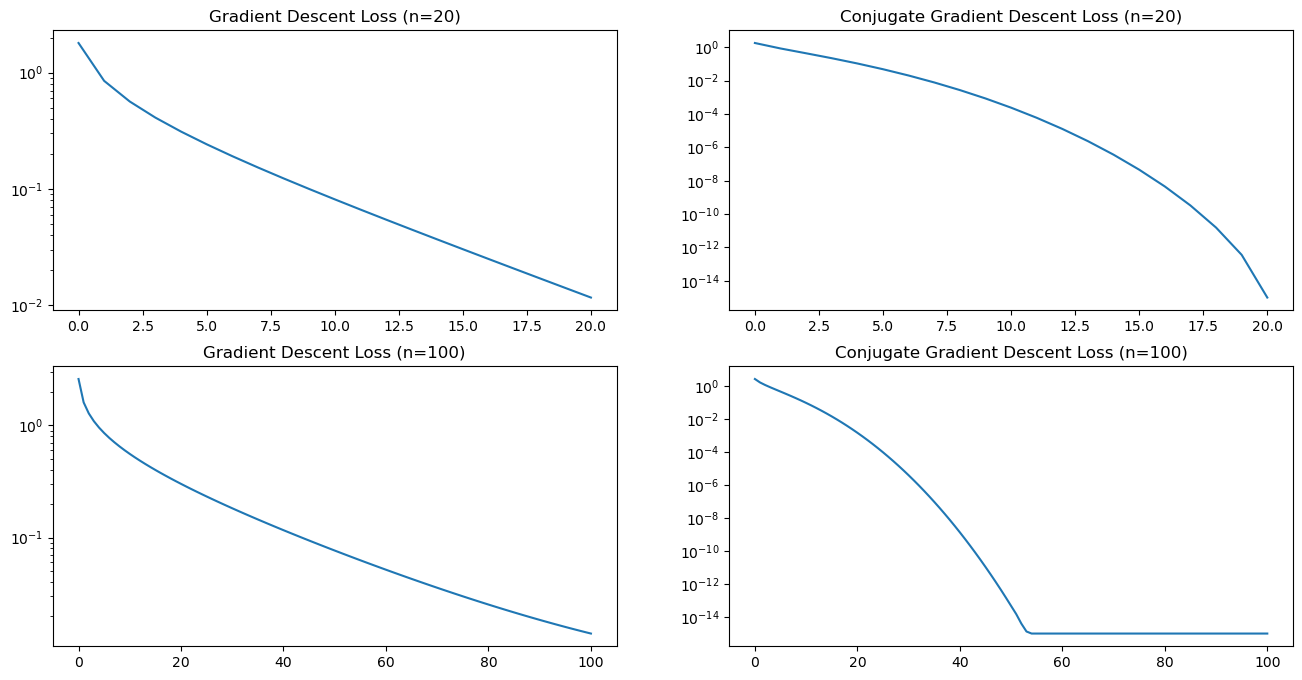

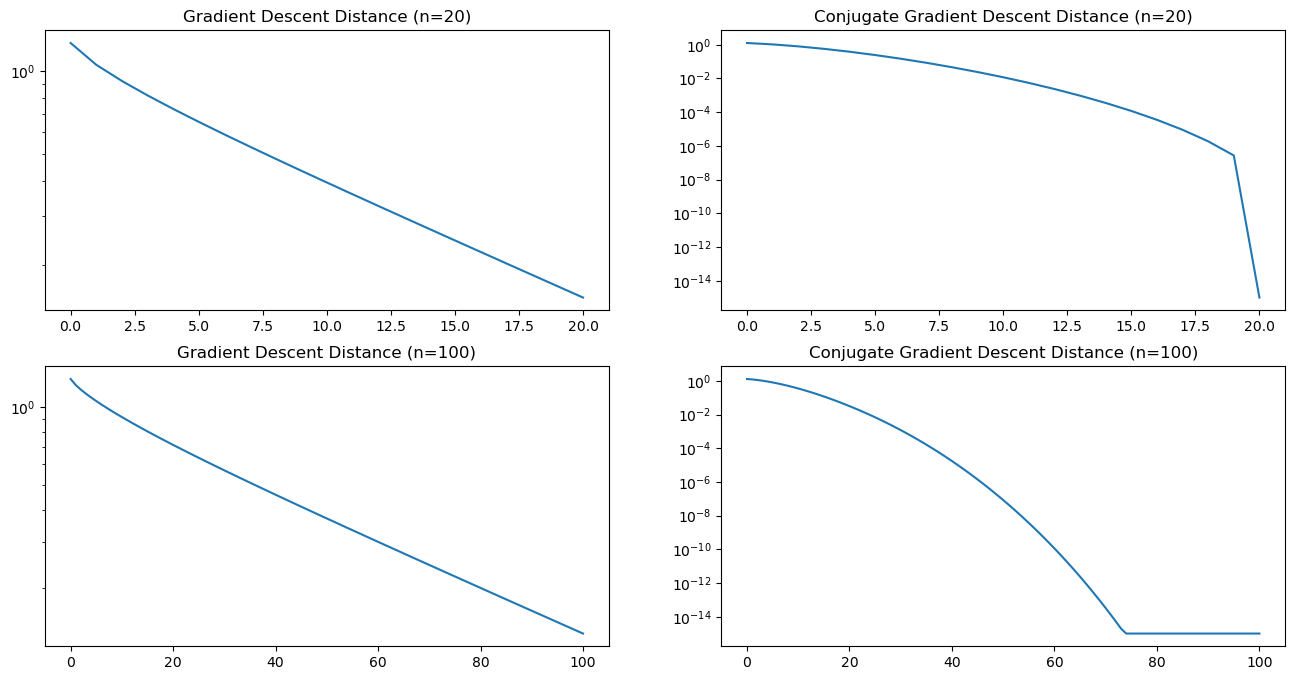

In [7]:
loss_fig, loss_ax = plt.subplots(2, 2, figsize=(16, 8))
dist_fig, dist_ax = plt.subplots(2, 2, figsize=(16, 8))

def plot(data, name, n, i, j):
    axes = {"Loss": loss_ax, "Distance": dist_ax}
    for k, (title, ax) in enumerate(axes.items()):
        ax[i, j].plot(np.clip(data[k], min=10e-16))
        ax[i, j].set_title(f'{name} {title} (n={n})')
        ax[i, j].set_yscale('log')
    
plot(gd_20, 'Gradient Descent', 20, 0, 0)
plot(gd_100, 'Gradient Descent', 100, 1, 0)
plot(cgd_20, 'Conjugate Gradient Descent', 20, 0, 1)
plot(cgd_100, 'Conjugate Gradient Descent', 100, 1, 1)

plt.show()